# Figure 2, Panel E

Heatmap of ridge regression coefficients for all chromatin features using only enhancers (-CTCF, -H3K4me3, -TSS) as inputs, as well as bar plot of feature importance (mean decrease in impurity) from random forest classifier (in the same order). 

*Output: PanelE.pdf*

# Setup

In [1]:
# Load packages
library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(here)
here::i_am("figures/Figure2/Panel_E/PanelE.ipynb")
here()
theme_set(theme_bw() + theme(panel.grid=element_blank(), axis.text=element_text(size=5)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure2/Panel_E

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         patchwork_1.3.0    RColorBrewer_1.1-3 lubridate_1.9.4   
 [5] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
 [9] readr_2.1.5        tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2     
[13] tidyverse_2.0.0   

loaded via a namespace (an

# Load ML Results

In [2]:
#load data
feature_importances <- read.delim(
    here(
        "inputs", "ReModEx", "GM12878", "enh_only",
        "dose_10uM", "feature_importance.csv"
    ),
    sep = ","
)

# Generate plots & assemble figure panel

Saving 5 x 7 in image


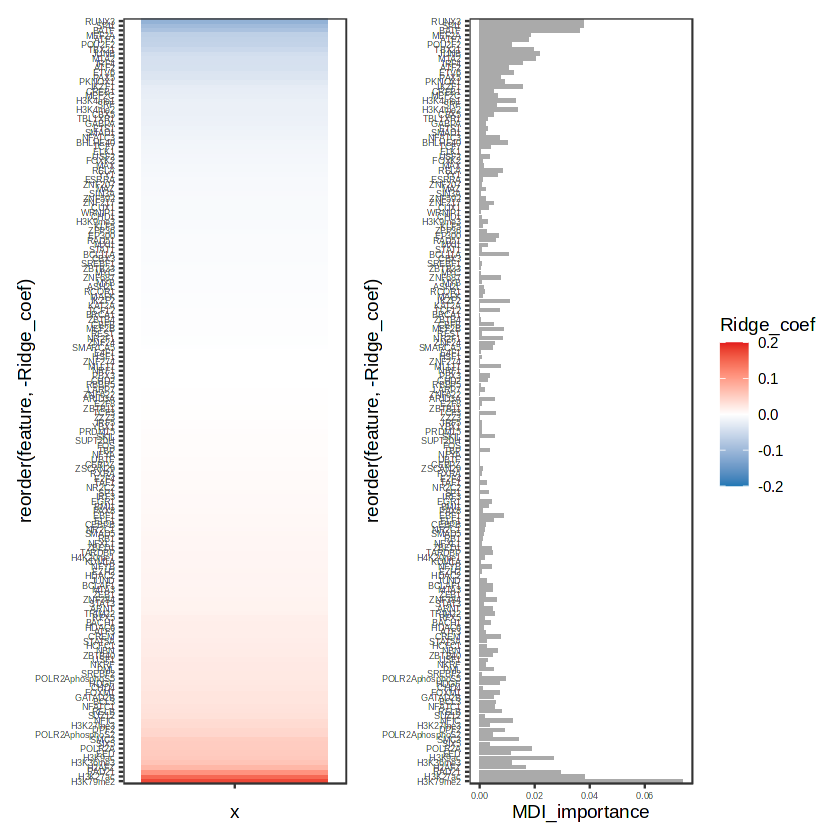

In [3]:
plot_Ridge <- 
    feature_importances %>% 
        ggplot(aes(x="", y=reorder(feature, -Ridge_coef), fill=Ridge_coef)) + 
        geom_tile() +
        scale_fill_gradient2(low=brewer.pal(3, "Paired")[2], mid="white", high=brewer.pal(6, "Paired")[6], limits=c(-0.2,0.2))

plot_MDI <-
    feature_importances %>% 
        ggplot(aes(x=MDI_importance, y=reorder(feature, -Ridge_coef))) + 
        geom_col(width=.75, fill="#aaaaaa")


(plot_Ridge | plot_MDI) + plot_layout(widths=c(1,1), guides="collect")
ggsave("PanelE.pdf", width=5)